### Javier Carballal Morgade
### Claudia Reyero Bardelás

# Exploring Basic Quantum Concepts in Qiskit

In this notebook we explore superposition, interference, entanglement, phase kickback, and measurement.

In [113]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, partial_trace
from qiskit_aer import AerSimulator
from qiskit.visualization import (
    plot_bloch_multivector,
    plot_histogram,
    plot_state_city,
    plot_state_qsphere,
)

simulator = AerSimulator()

def sample_counts(circuit, shots=1024):
    """Run a circuit that already contains measurements."""
    compiled = transpile(circuit, simulator)
    return simulator.run(compiled, shots=shots).result().get_counts()

## Superposition

To explore superposition, we can use this simple circuit with just one Hadamard gate.

Qubits in qiskit start in $|0\rangle$. The Hadamard gate acts as

$$H|0\rangle=|+\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}}.$$

The amplitudes corresponding to the computational basis have both magnitude $1/\sqrt{2}$, so each outcome has probability $1/2$. On the Bloch sphere, $H$ rotates $+Z$ to $+X$.

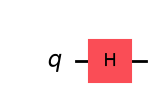

<IPython.core.display.Latex object>

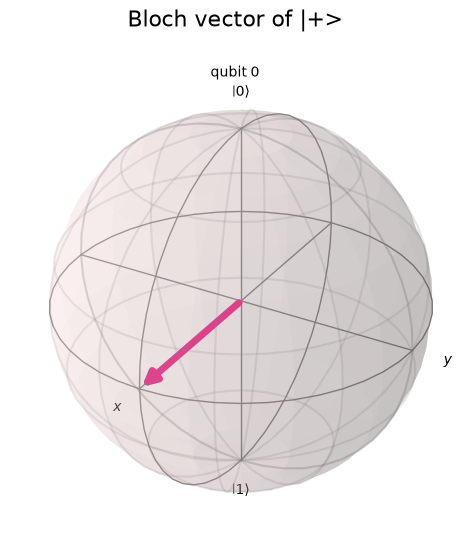

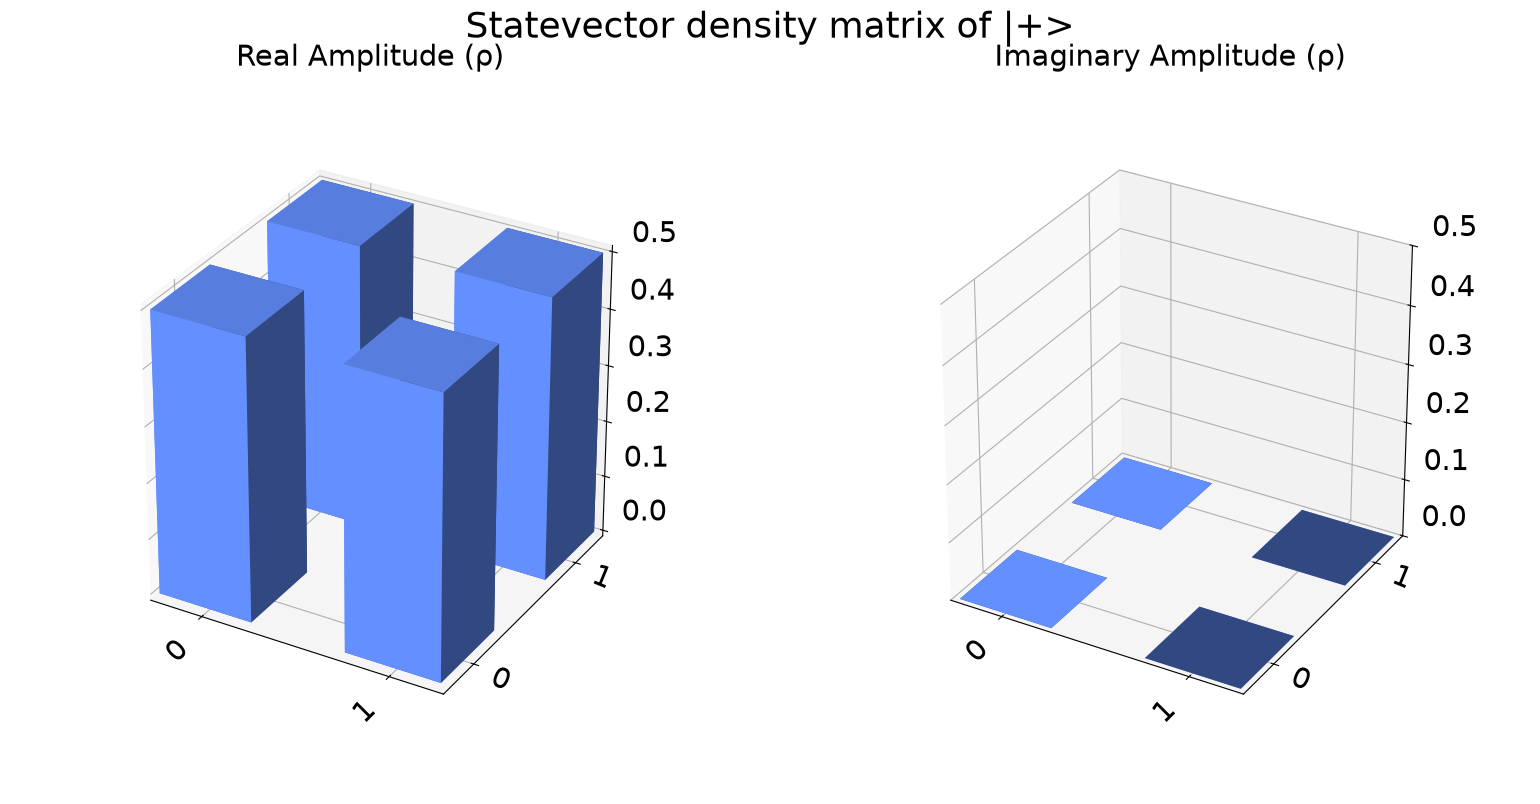

In [114]:
hadamard_circuit = QuantumCircuit(1)
hadamard_circuit.h(0)

hadamard_state = Statevector.from_instruction(hadamard_circuit)
display(hadamard_circuit.draw("mpl"))
display(hadamard_state.draw("latex"))
display(plot_bloch_multivector(hadamard_state, title="Bloch vector of |+>"))
display(plot_state_city(hadamard_state, title="Statevector density matrix of |+>"))

As we can see, the state in the Bloch sphere is at equal distance from $|0\rangle$ and $|1\rangle$. In the city plot, the diagonal elements, which represent the actual probabilities of measuring a state, are of equal height. The qubit is in a superposition between $|0\rangle$ and $|1\rangle$.

## Measurement and number of shots

Following with the last circuit, one measurement shot returns `0` or `1` and collapses the qubit to that state. If we want to estimate the actual probability distribution for the final state, we must repeat the experiment multiple times. The more shots used, the less sample noise and better approximation.

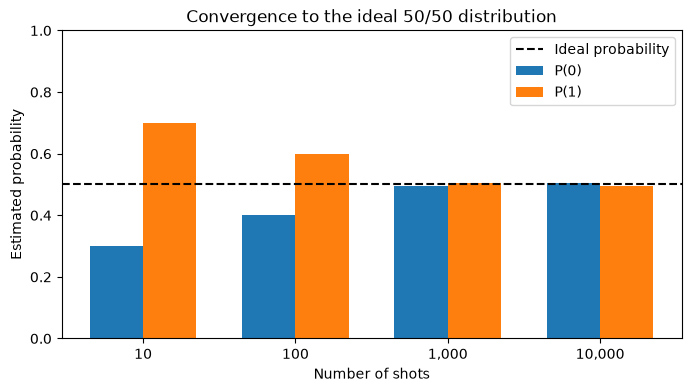

In [127]:
measured_hadamard = hadamard_circuit.copy()
measured_hadamard.measure_all()

shot_values = [10, 100, 1000, 10000]
shot_counts = [sample_counts(measured_hadamard, shots) for shots in shot_values]

probabilities = np.array([
    [counts.get("0", 0) / shots, counts.get("1", 0) / shots]
    for shots, counts in zip(shot_values, shot_counts)
])

x = np.arange(len(shot_values))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - width / 2, probabilities[:, 0], width, label="P(0)")
ax.bar(x + width / 2, probabilities[:, 1], width, label="P(1)")
ax.axhline(0.5, color="black", linestyle="--", label="Ideal probability")
ax.set_xticks(x, [f"{shots:,}" for shots in shot_values])
ax.set_ylim(0, 1)
ax.set_xlabel("Number of shots")
ax.set_ylabel("Estimated probability")
ax.set_title("Convergence to the ideal 50/50 distribution")
ax.legend()
plt.show()

We can see that there is a 50/50 chance of measuring either value, and increasing the number of shots gives more accurate and stable results.

## Interference and relative phase

In quantum mechanics, a global phase has no measurable effects on the system but a relative phase, even if on itself it doesn't alter the probability distribtions, can create interference when chaining operations that create measurable differences. To illustrate this, let's consider $H\,P(\phi)\,H$, where $ P(\phi)\ $ is a phase gate.

Before the final $H$, the state is $(|0\rangle+e^{i\phi}|1\rangle)/\sqrt{2}$. The final gate converts phase into probability:

$$P(0)=\cos^2(\phi/2),\qquad P(1)=\sin^2(\phi/2).$$

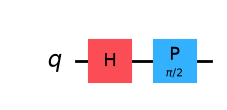

<IPython.core.display.Latex object>

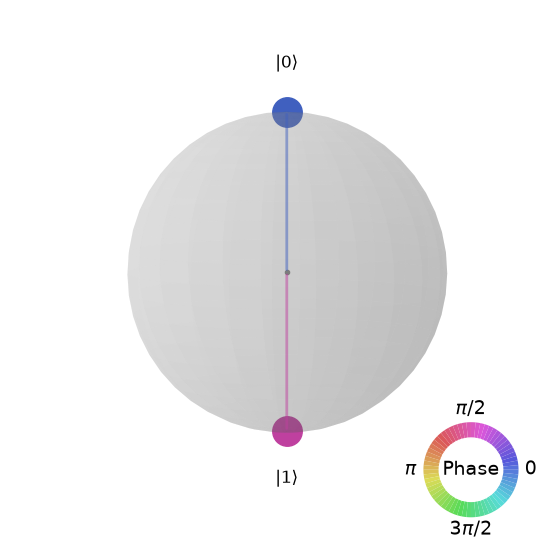

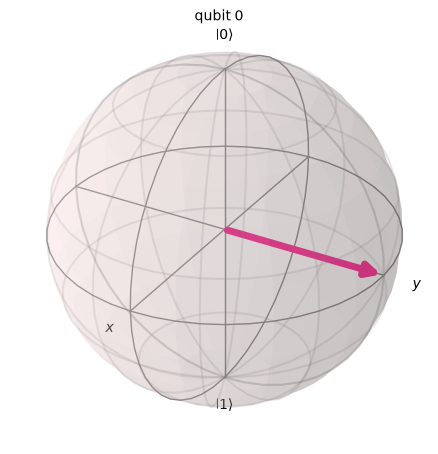

In [128]:
phi = np.pi / 2
phase_only = QuantumCircuit(1)
phase_only.h(0)
phase_only.p(phi, 0)
phase_state = Statevector.from_instruction(phase_only)

display(phase_only.draw("mpl"))
display(phase_state.draw("latex"))
display(plot_state_qsphere(phase_state))
display(plot_bloch_multivector(phase_state))

If we plot the probability of obtaining both basis values after measuring for each value of $\phi$, we can see that it alternates between every probability distribution between measuring state $|0\rangle$, $|1\rangle$, or a combination of the two. This setup managed to turn the hidden relative phase into a measurable outcome.

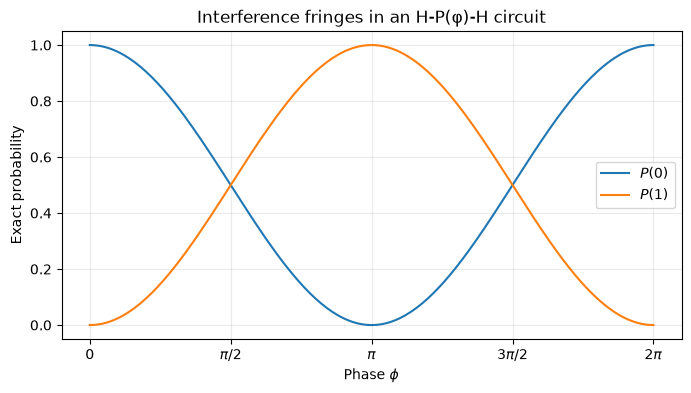

In [117]:
def interferometer(phi):
    circuit = QuantumCircuit(1)
    circuit.h(0)
    circuit.p(phi, 0)
    circuit.h(0)
    return circuit


phases = np.linspace(0, 2 * np.pi, 201)
p0 = [Statevector.from_instruction(interferometer(angle)).probabilities()[0] for angle in phases]

plt.figure(figsize=(8, 4))
plt.plot(phases, p0, label=r"$P(0)$")
plt.plot(phases, 1 - np.asarray(p0), label=r"$P(1)$")
plt.xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    [r"$0$", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"],
)
plt.xlabel(r"Phase $\phi$")
plt.ylabel("Exact probability")
plt.title("Interference fringes in an H-P(φ)-H circuit")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

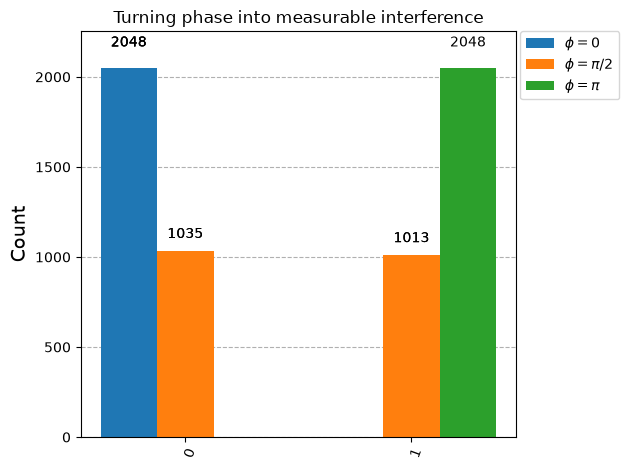

In [118]:
selected_phases = [0, np.pi / 2, np.pi]
interference_counts = []

for angle in selected_phases:
    circuit = interferometer(angle)
    circuit.measure_all()
    interference_counts.append(sample_counts(circuit, shots=2048))

display(plot_histogram(
    interference_counts,
    legend=[r"$\phi=0$", r"$\phi=\pi/2$", r"$\phi=\pi$"],
    title="Turning phase into measurable interference",
))

## Entanglement

In order to illustrate entanglement, we explore the Bell states. A Hadamard on qubit 0 followed by a CNOT creates

$$|\Phi^+\rangle=\frac{|00\rangle+|11\rangle}{\sqrt{2}}.$$

The Hadamard creates two alternatives and the CNOT correlates them. The result cannot be factored into separate qubit states, so it is entangled. Local $X$ and $Z$ gates produce the other Bell states.

Phi+: amplitudes = [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j], reduced-qubit purity = 0.500
Phi-: amplitudes = [ 0.707+0.j -0.   +0.j  0.   +0.j -0.707+0.j], reduced-qubit purity = 0.500
Psi+: amplitudes = [0.   +0.j 0.707+0.j 0.707+0.j 0.   +0.j], reduced-qubit purity = 0.500
Psi-: amplitudes = [ 0.   +0.j -0.707+0.j  0.707+0.j -0.   +0.j], reduced-qubit purity = 0.500


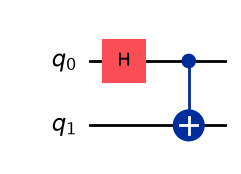

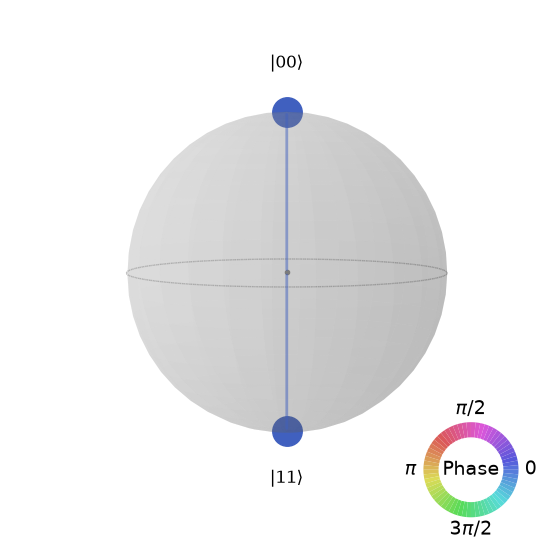

In [119]:
def bell_circuit(label):
    circuit = QuantumCircuit(2)
    circuit.h(0)
    circuit.cx(0, 1)

    if label.startswith("Psi"):
        circuit.x(1)
    if label.endswith("-"):
        circuit.z(0)
    return circuit


bell_labels = ["Phi+", "Phi-", "Psi+", "Psi-"]
bell_states = {label: Statevector.from_instruction(bell_circuit(label)) for label in bell_labels}

for label, state in bell_states.items():
    reduced_q0 = partial_trace(state, [1])
    purity = np.real(np.trace(reduced_q0.data @ reduced_q0.data))
    print(f"{label:4s}: amplitudes = {np.round(state.data, 3)}, reduced-qubit purity = {purity:.3f}")

display(bell_circuit("Phi+").draw("mpl"))
display(plot_state_qsphere(bell_states["Phi+"]))

Each Bell state is pure, but either qubit alone has state $I/2$ and purity $\operatorname{Tr}(\rho^2)=1/2$: a signature of entanglement. Q-sphere colors show the relative phases.

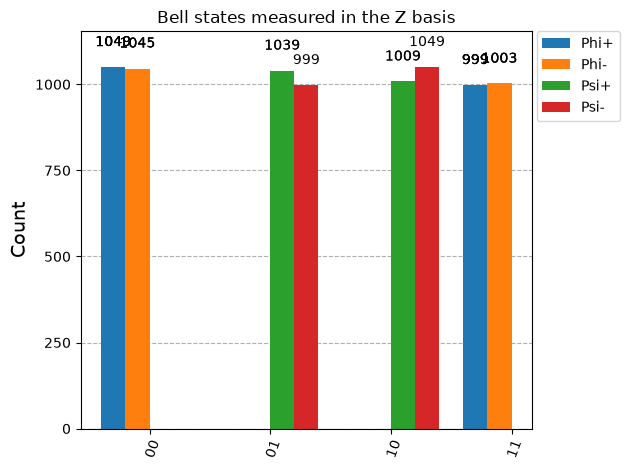

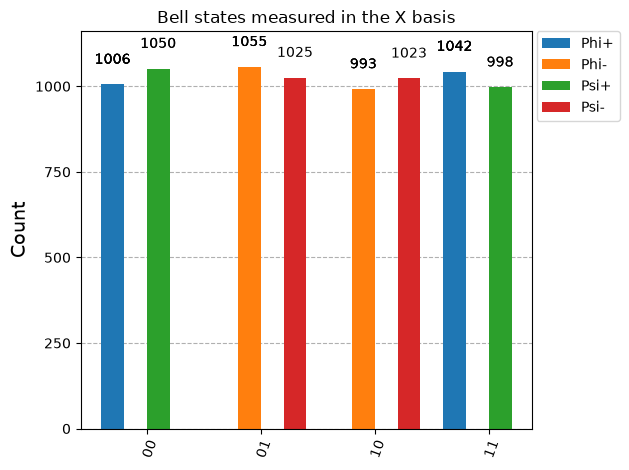

In [120]:
def measure_bell(label, basis="Z", shots=2048):
    circuit = bell_circuit(label)
    if basis == "X":
        # H maps an X-basis measurement onto the usual Z-basis measurement.
        circuit.h([0, 1])
    circuit.measure_all()
    return sample_counts(circuit, shots)


bell_z_counts = [measure_bell(label, "Z") for label in bell_labels]
bell_x_counts = [measure_bell(label, "X") for label in bell_labels]

display(plot_histogram(
    bell_z_counts,
    legend=bell_labels,
    title="Bell states measured in the Z basis",
))
display(plot_histogram(
    bell_x_counts,
    legend=bell_labels,
    title="Bell states measured in the X basis",
))

**Interpretation.** In the $Z$ basis, $\Phi$ gives equal bits (`00`, `11`) and $\Psi$ gives opposite bits (`01`, `10`). The sign is invisible because it changes phase, not magnitude.

In the $X$ basis, interference reveals the sign: `+` gives equal results and `-` gives opposite results.

A first measurement is random and collapses the pair; the second result follows the correlation. Each local result alone remains random.

## Phase kickback

CNOT applies $X$ to its target when the control is $|1\rangle$. Since $|+\rangle$ and $|-\rangle$ are $X$ eigenstates,

$$X|+\rangle=+|+\rangle,\qquad X|-\rangle=-|-\rangle.$$

The target remains unchanged, but its eigenvalue is transferred as a phase to the control. A final Hadamard gives control `1` for target $|-\rangle$ and `0` for target $|+\rangle$.

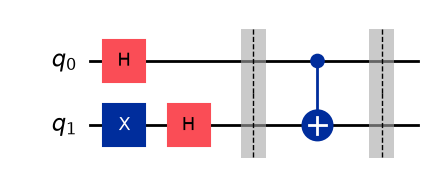

<IPython.core.display.Latex object>

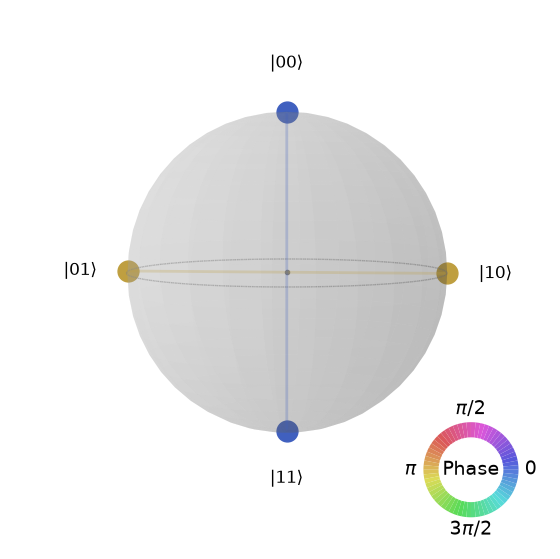

In [121]:
def kickback_circuit(target_sign="-", include_final_h=True):
    circuit = QuantumCircuit(2)
    circuit.h(0)  # control = |+>

    if target_sign == "-":
        circuit.x(1)
    circuit.h(1)  # target = |+> or |->

    circuit.barrier()
    circuit.cx(0, 1)
    circuit.barrier()

    if include_final_h:
        circuit.h(0)
    return circuit


minus_kickback = kickback_circuit("-", include_final_h=False)
minus_state = Statevector.from_instruction(minus_kickback)
display(minus_kickback.draw("mpl"))
display(minus_state.draw("latex"))
display(plot_state_qsphere(minus_state))

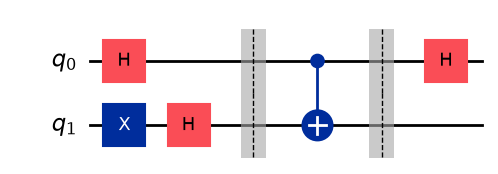

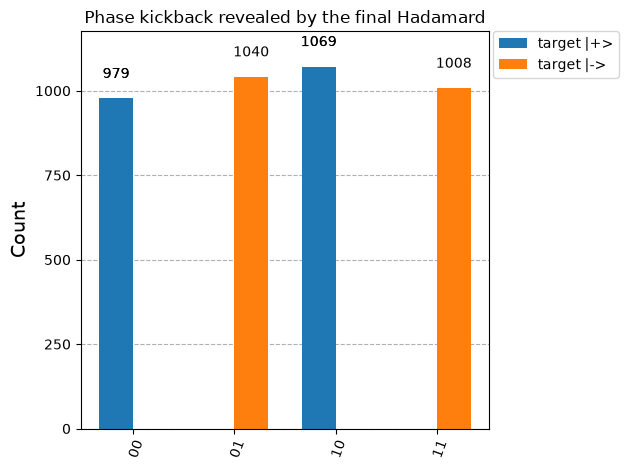

Remember: Qiskit writes |q1 q0>; q0 is the control and rightmost measured bit.


In [122]:
kickback_counts = []
for sign in ["+", "-"]:
    circuit = kickback_circuit(sign, include_final_h=True)
    circuit.measure_all()
    kickback_counts.append(sample_counts(circuit, shots=2048))

display(kickback_circuit("-", include_final_h=True).draw("mpl"))
display(plot_histogram(
    kickback_counts,
    legend=["target |+>", "target |->"],
    title="Phase kickback revealed by the final Hadamard",
))
print("Remember: Qiskit writes |q1 q0>; q0 is the control and rightmost measured bit.")

**Interpretation.** The target bit is random, but the rightmost control bit is deterministic: `0` for target $|+\rangle$, `1` for $|-\rangle$. This is how algorithms encode information in phases for later interference.